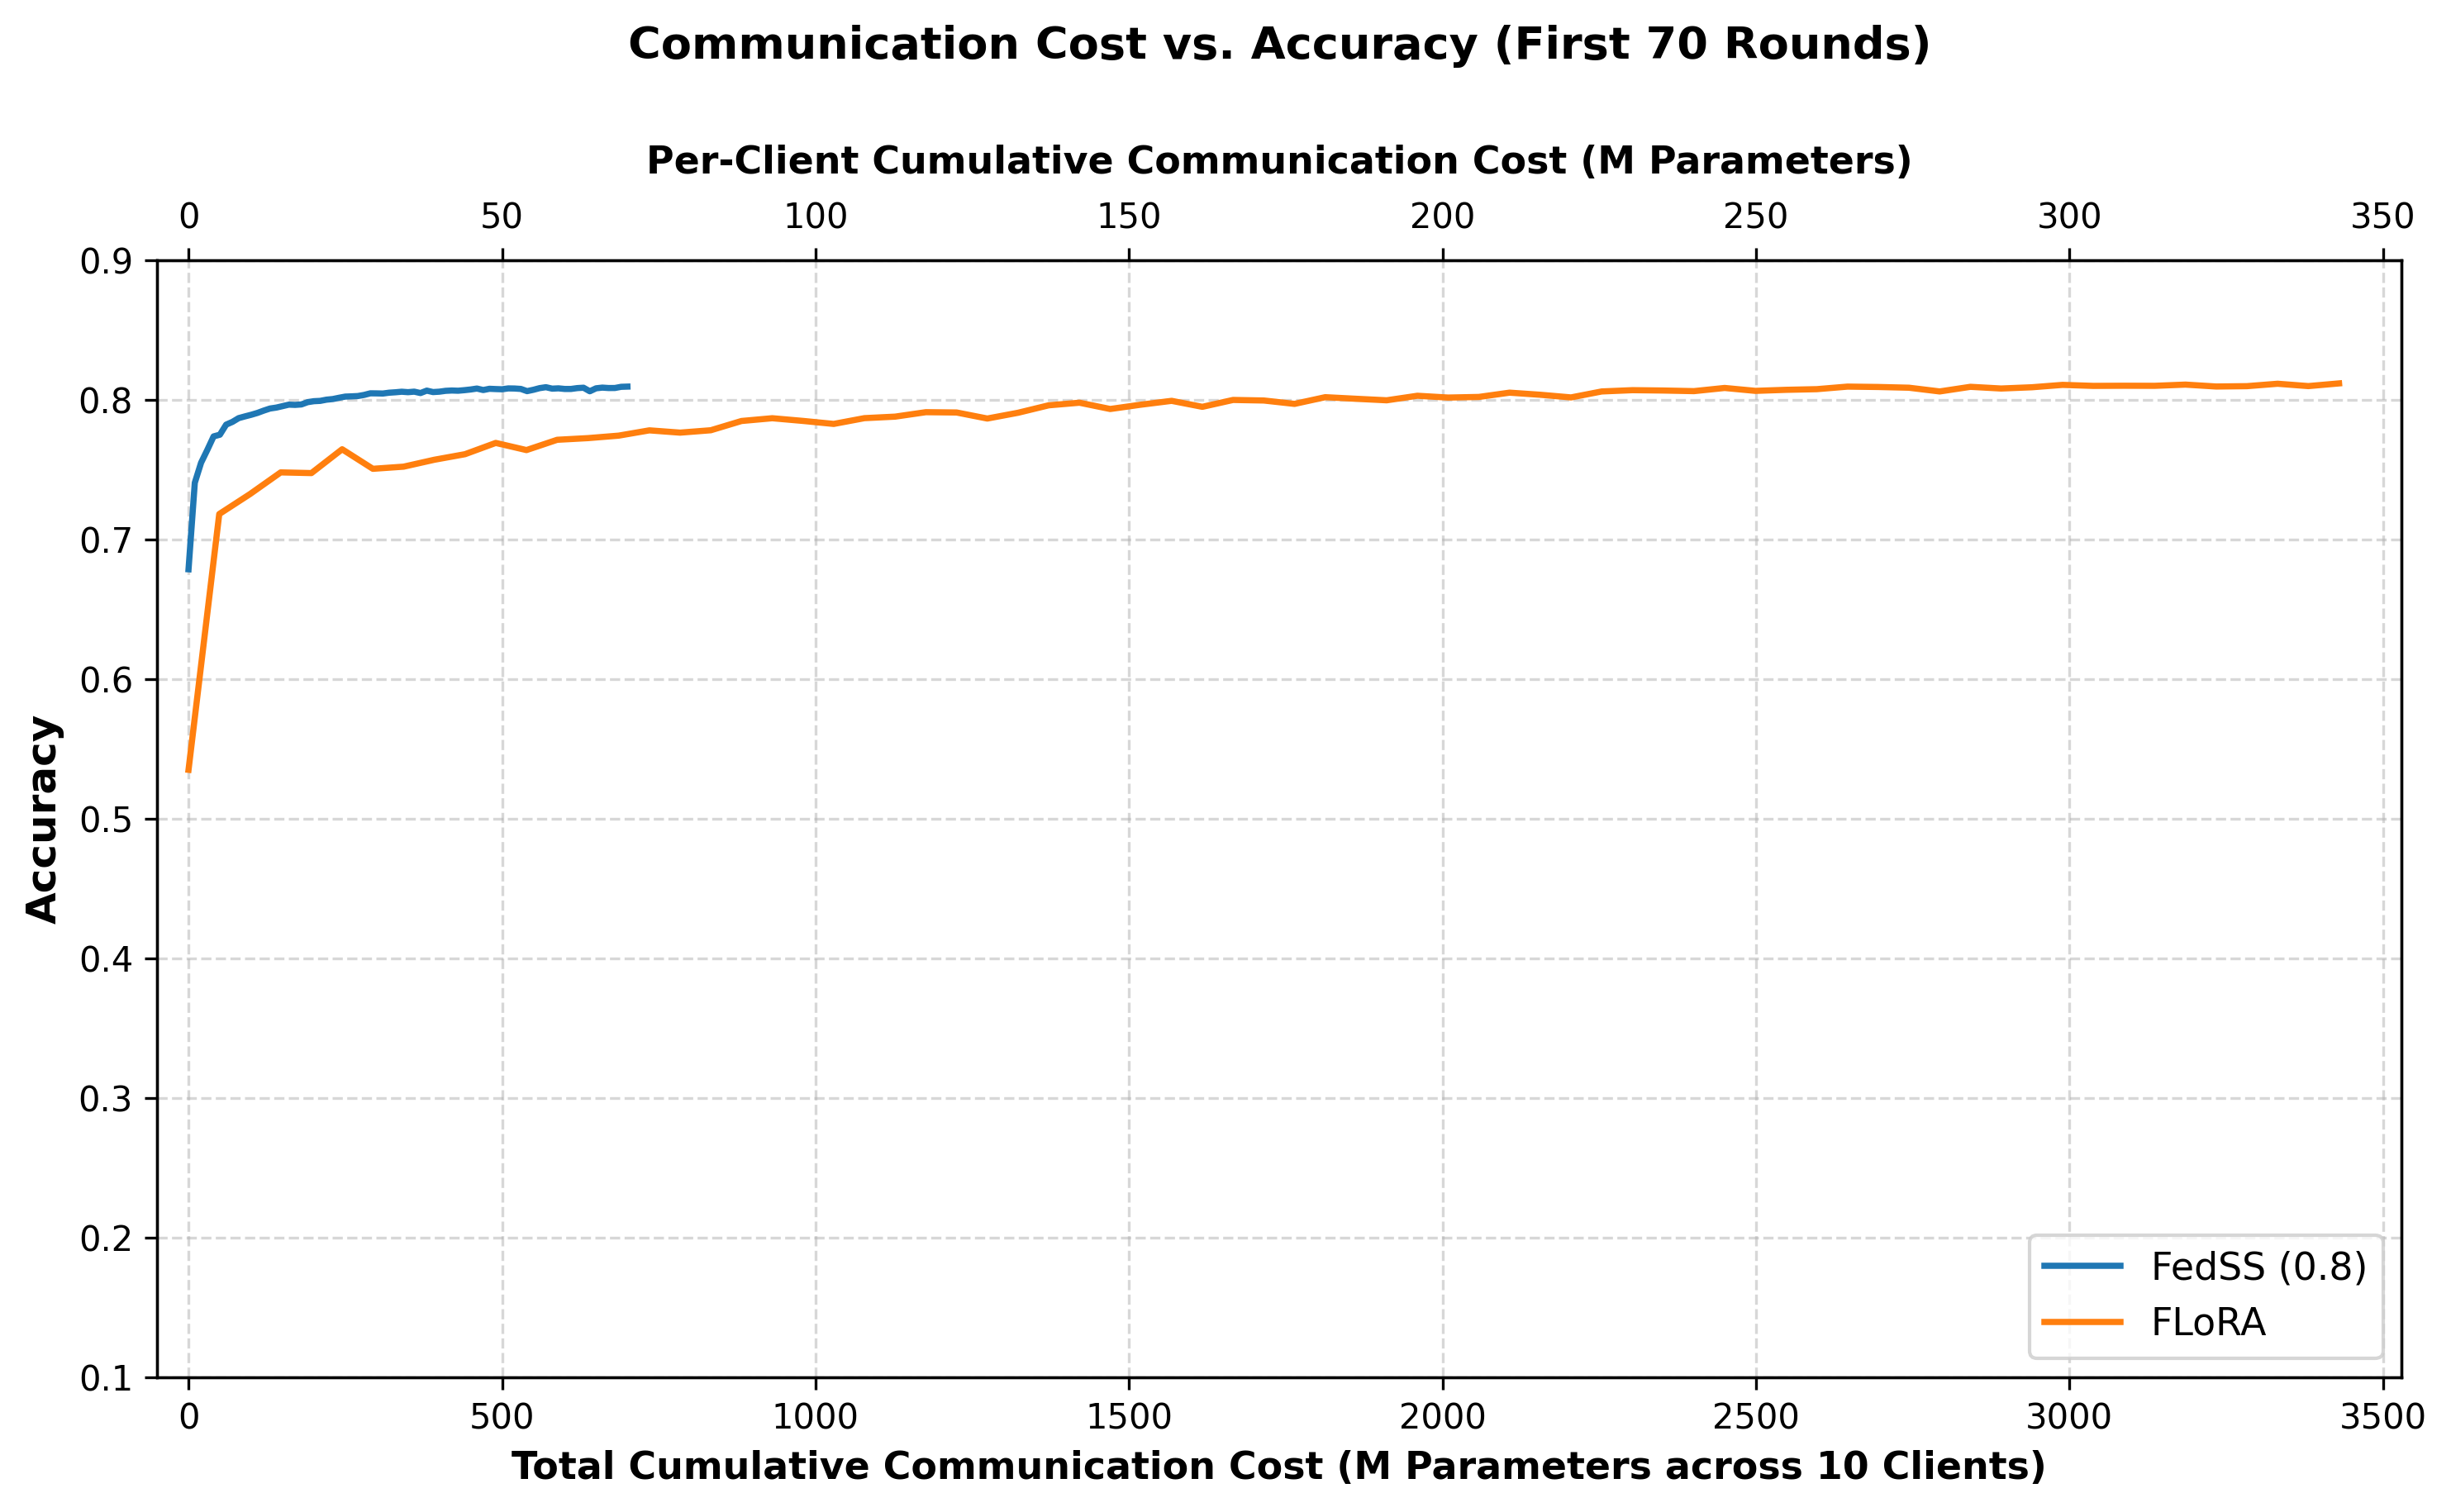

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. 数据读取与处理
f1 = (
    "qqp_fedss_08_dirichlet_0_4_10_-train-20260726_053127-81041383c90a1607.csv"
)
f2 = (
    "qqp_flora_dirichlet_0_4_10_-train-20260730_135656-f07727b4aece6527.csv"
)


def load_and_process(filepath, cost_per_client_per_round, num_clients=10):
    df = pd.read_csv(filepath, header=1)
    df["round"] = pd.to_numeric(df["round"], errors="coerce")
    df["accuracy"] = pd.to_numeric(df["accuracy"], errors="coerce")
    df = df.dropna(subset=["round", "accuracy"])

    # 截取前 70 轮数据
    df = df[df["round"] <= 70].copy()

    # 计算累计通信开销（M Parameters）
    df["cost_per_client_M"] = df["round"] * cost_per_client_per_round
    df["cost_total_M"] = df["cost_per_client_M"] * num_clients
    return df


# FedSS 每轮 1.0M/client，FLoRA 每轮 4.9M/client
df_fedss = load_and_process(f1, cost_per_client_per_round=1.0, num_clients=10)
df_flora = load_and_process(f2, cost_per_client_per_round=4.9, num_clients=10)

# 2. 绘图
fig, ax1 = plt.subplots(figsize=(10, 6.2), dpi=300)

ax1.plot(
    df_fedss["cost_total_M"],
    df_fedss["accuracy"],
    label="FedSS (0.8)",
    color="#1f77b4",
    linewidth=1.8,
)
ax1.plot(
    df_flora["cost_total_M"],
    df_flora["accuracy"],
    label="FLoRA",
    color="#ff7f0e",
    linewidth=1.8,
)

# 下坐标轴 (Total Cost)
ax1.set_xlabel(
    "Total Cumulative Communication Cost (M Parameters across 10 Clients)",
    fontsize=11,
    fontweight="bold",
)
ax1.set_ylabel("Accuracy", fontsize=12, fontweight="bold")
ax1.set_title(
    "Communication Cost vs. Accuracy (First 70 Rounds)",
    fontsize=13,
    fontweight="bold",
    pad=25,
)
ax1.grid(True, linestyle="--", alpha=0.5)

# 设置 X 轴与 Y 轴范围 [0.1, 0.9]
max_flora_cost = df_flora["cost_total_M"].max()
ax1.set_xlim(-50, max_flora_cost + 100)
ax1.set_ylim(0.1, 0.9)

# 上坐标轴 (Per-Client Cost)
ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())

ticks_total = [0, 500, 1000, 1500, 2000, 2500, 3000, 3500]
ax1.set_xticks([t for t in ticks_total if t <= max_flora_cost + 100])
ax2.set_xticks([t for t in ticks_total if t <= max_flora_cost + 100])
ax2.set_xticklabels([f"{x/10:.0f}" for x in ax2.get_xticks()])
ax2.set_xlabel(
    "Per-Client Cumulative Communication Cost (M Parameters)",
    fontsize=11,
    fontweight="bold",
    labelpad=8,
)

ax1.legend(loc="lower right", fontsize=11)

plt.tight_layout()
plt.savefig("comm_cost_vs_accuracy_no_max.png")
plt.show()